# 10 · Inventory Optimisation

Convert demand forecasts into a reorder policy: safety stock, reorder point, EOQ and a stock-status classification that flags stock-outs and overstock *before* they hurt.

In [1]:
import sys, warnings, logging
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)

from src.config import *
from src.ingestion.etl import load_processed
D = load_processed()
tx, customers, products, inventory = D["transactions"], D["customers"], D["products"], D["inventory"]
daily = D["daily"]
print(f"Loaded {len(tx):,} clean transaction lines | {tx.customer_id.nunique():,} customers | "
      f"{tx.order_date.min().date()} -> {tx.order_date.max().date()}")

Loaded 54,339 clean transaction lines | 1,455 customers | 2024-01-01 -> 2025-12-31


## 1. Product-level demand
The total-demand ensemble forecast is allocated top-down to products by their trailing 90-day share of units.

In [2]:
from src.forecasting.ensemble import available_models, run_forecasting, allocate_to_products
res = run_forecasting(daily.set_index("date")["units"], available_models(skip_lstm=True))
demand = allocate_to_products(res["future"], D["product_daily"])
demand.sort_values("forecast_units_horizon", ascending=False).head(8).round(2)

,product_id,share,forecast_units_horizon,forecast_daily_mean,hist_daily_mean,hist_daily_std
21,P022,0.08,248.53,8.28,9.53,4.26
0,P001,0.05,163.08,5.44,6.26,5.11
19,P020,0.05,151.79,5.06,5.82,3.53
20,P021,0.05,151.79,5.06,5.82,4.53
29,P030,0.04,140.20,4.67,5.38,3.56
36,P037,0.04,137.59,4.59,5.28,2.88
11,P012,0.04,130.06,4.34,4.99,3.18
22,P023,0.04,126.30,4.21,4.84,3.03


## 2. Policy
- **Safety stock** = z · σ_daily · √lead-time (z from the service level)
- **Reorder point** = forecast daily demand × lead-time + safety stock
- **EOQ** = √(2·D·S / H) with D annual demand, S order cost, H = unit cost × holding rate
- **Order-up-to** = reorder point + EOQ

In [3]:
from src.inventory.optimizer import optimize_inventory
plan = optimize_inventory(inventory, demand, service_level=SERVICE_LEVEL).merge(products[["product_id", "product_name"]], on="product_id")
print(plan.status.value_counts().to_dict())
plan[["product_id", "product_name", "status", "current_stock", "days_of_cover", "safety_stock", "reorder_point", "eoq", "recommended_order_qty"]].sort_values("days_of_cover").head(12)

{'Healthy': 26, 'Overstock': 10, 'Reorder': 3, 'Critical': 1}


,product_id,product_name,status,current_stock,days_of_cover,safety_stock,reorder_point,eoq,recommended_order_qty
39,P040,Beauty Item 40,Critical,8,5.9,12,35,116,143
12,P013,Apparel Item 13,Healthy,36,15.0,9,26,95,0
5,P006,Grocery Item 6,Reorder,44,16.9,24,76,204,236
22,P023,Apparel Item 23,Healthy,77,18.3,9,22,147,0
21,P022,Electronics Item 22,Healthy,159,19.2,23,106,124,0
19,P020,Beauty Item 20,Healthy,110,21.7,11,27,257,0
1,P002,Electronics Item 2,Healthy,27,21.8,7,17,46,0
38,P039,Home & Kitchen Item 39,Healthy,67,22.5,12,36,152,0
30,P031,Grocery Item 31,Reorder,59,24.4,24,63,278,282
34,P035,Beauty Item 35,Reorder,42,24.4,15,48,160,166


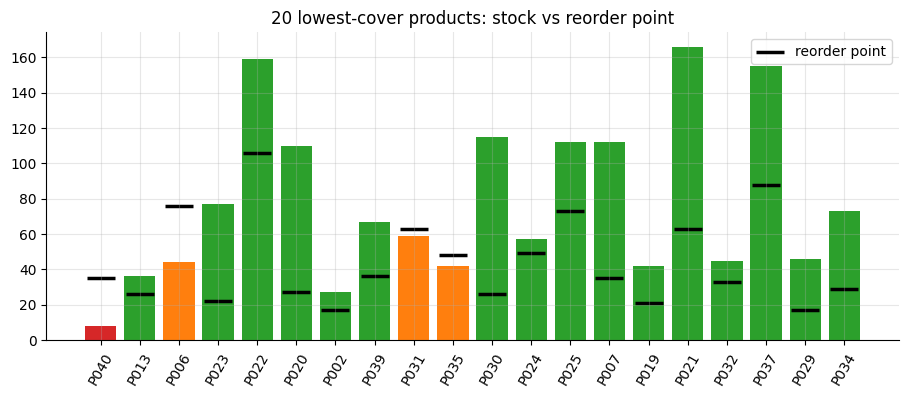

In [4]:
colors = {"Critical": "#d62728", "Reorder": "#ff7f0e", "Healthy": "#2ca02c", "Overstock": "#1f77b4"}
p = plan.sort_values("days_of_cover").head(20)
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(p.product_id, p.current_stock, color=[colors[s] for s in p.status])
ax.scatter(p.product_id, p.reorder_point, color="k", marker="_", s=400, lw=2.5, label="reorder point")
ax.set_title("20 lowest-cover products: stock vs reorder point"); ax.legend(); plt.xticks(rotation=60); plt.show()

## 3. Trade-off: service level vs. working capital

 service_level  safety_units  safety_stock_value_$  critical_products
           1.0           287               12655.0                  0
           1.0           427               18623.0                  1
           1.0           541               23451.0                  1
           1.0           641               27847.0                  1
           1.0           756               32751.0                  1
           1.0           836               36367.0                  1


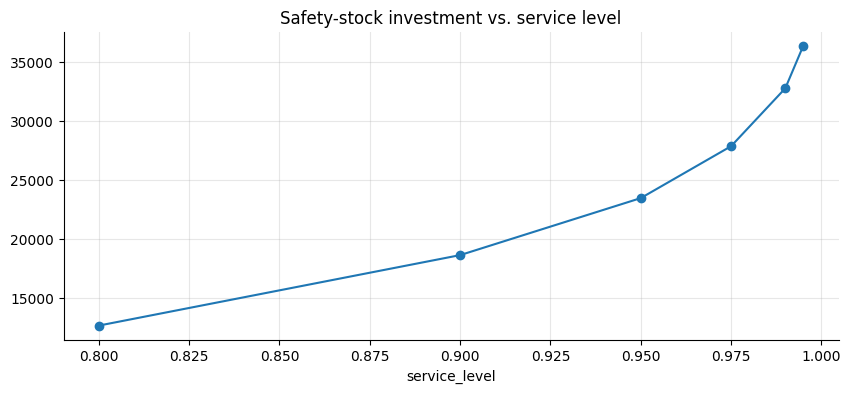

In [5]:
rows = []
for sl in (0.80, 0.90, 0.95, 0.975, 0.99, 0.995):
    q = optimize_inventory(inventory, demand, service_level=sl)
    rows.append((sl, q.safety_stock.sum(), (q.safety_stock * q.unit_cost).sum(), (q.status == "Critical").sum()))
t = pd.DataFrame(rows, columns=["service_level", "safety_units", "safety_stock_value_$", "critical_products"])
print(t.round(0).to_string(index=False))
t.set_index("service_level")["safety_stock_value_$"].plot(marker="o", title="Safety-stock investment vs. service level"); plt.show()

## 4. Action list

In [6]:
po = plan[plan.recommended_order_qty > 0][["product_id", "product_name", "supplier", "status", "recommended_order_qty", "order_cost_estimate"]]
print(f"{len(po)} purchase orders suggested, total ${po.order_cost_estimate.sum():,.0f}")
po

4 purchase orders suggested, total $11,050


,product_id,product_name,supplier,status,recommended_order_qty,order_cost_estimate
5,P006,Grocery Item 6,Globex Traders,Reorder,236,2428.44
30,P031,Grocery Item 31,Globex Traders,Reorder,282,1824.54
34,P035,Beauty Item 35,Acme Supply,Reorder,166,2632.76
39,P040,Beauty Item 40,Umbrella Logistics,Critical,143,4164.16


In [7]:
ex = plan[plan.status == "Overstock"]
print(f"{len(ex)} overstocked SKUs tie up ${ex.excess_value.sum():,.0f} of excess inventory (above order-up-to level)")
ex[["product_id", "product_name", "current_stock", "days_of_cover", "excess_units", "excess_value"]].sort_values("excess_value", ascending=False).head(8)

10 overstocked SKUs tie up $55,257 of excess inventory (above order-up-to level)


,product_id,product_name,current_stock,days_of_cover,excess_units,excess_value
11,P012,Electronics Item 12,362,83.5,251,47065.01
26,P027,Electronics Item 27,152,63.0,36,4791.24
16,P017,Electronics Item 17,92,80.1,17,2504.44
3,P004,Home & Kitchen Item 4,101,83.7,18,896.04
7,P008,Apparel Item 8,79,63.4,0,0.00
14,P015,Beauty Item 15,86,63.2,0,0.00
17,P018,Apparel Item 18,73,80.4,0,0.00
25,P026,Grocery Item 26,289,83.6,0,0.00
